# Exploratory Data Analysis (EDA): Bus Trip Demand Forecasting

**Objective:** Understand passenger demand patterns, inspect data quality issues (missing values, typos, duplicates), and prepare features for predicting `passengers` 7 days before departure.

### 1. Imports and Setup

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set display and visual styles
pd.set_option('display.max_columns', None)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
%matplotlib inline

print("Libraries loaded successfully!")

Libraries loaded successfully!


### 2. Load the Dataset

In [2]:
# Load bus trips data
df = pd.read_csv('data/bus_trips.csv')
df['departure_datetime'] = pd.to_datetime(df['departure_datetime'])

print(f"Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")
df.head()

Dataset Shape: 19,934 rows, 18 columns

,trip_id,route_id,origin,destination,distance_km,route_type,departure_datetime,weekday,month,season,is_holiday,is_weekend,is_peak,capacity,base_fare,days_to_departure,passengers,occupancy
0,T000000,R03,Delhi,Jaipur,280.0,commuter,2024-11-01 06:00:00,4,11,autumn,1,0,1,45,495.0,7,45,1.0000
1,T000001,R01,Delhi,Chandigarh,250.0,commuter,2024-11-01 06:30:00,4,11,autumn,1,0,1,52,440.0,7,52,1.0000
2,T000002,R06,Delhi,Dehradun,255.0,tourist,2024-11-01 06:30:00,4,11,autumn,1,0,1,45,560.0,7,44,0.9778
3,T000003,R09,Ludhiana,Chandigarh,100.0,commuter,2024-11-01 06:30:00,4,11,autumn,1,0,1,30,175.0,7,18,0.6000
4,T000004,R02,Chandigarh,Manali,NaN,tourist,2024-11-01 07:00:00,4,11,autumn,1,0,1,40,680.0,7,36,0.9000


### 3. Data Hygiene & Quality Checks
Check for intentional real-world flaws: missing values, duplicate records, and entry errors.

In [3]:
# 1. Ensure departure_datetime is datetime
df['departure_datetime'] = pd.to_datetime(df['departure_datetime'])

# 2. Missing values
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
print("=== Missing Values ===")
print(missing_df[missing_df['Missing Count'] > 0])

# 3. Duplicate rows & over-capacity outliers
n0 = len(df)
n_dups = df.duplicated().sum()
over_capacity = df[df['passengers'] > df['capacity']]
n_bad = len(over_capacity)
print(f"\nrows: {n0} | duplicates: {n_dups} | over-capacity: {n_bad}")

# 4. Zero-passengers trips analysis (caused by disruptions like heavy rain / strikes)
zeros = df[df['passengers'] == 0]
print(f"\n=== Zero-Passenger Trips ({len(zeros)} total) ===")
print("Top dates with zero passengers:")
print(zeros.groupby(zeros['departure_datetime'].dt.date).size().sort_values(ascending=False).head(10))
print("\nRoutes most affected by zero passengers:")
print(zeros['route_id'].value_counts().head())

=== Missing Values ===
             Missing Count  Missing %
distance_km            387       1.94
base_fare              376       1.89

rows: 19934 | duplicates: 40 | over-capacity: 89

=== Zero-Passenger Trips (60 total) ===
Top dates with zero passengers:
departure_datetime
2024-12-23    2
2025-01-01    2
2026-09-07    2
2026-05-13    2
2026-04-21    2
2026-03-13    2
2025-01-28    1
2025-03-26    1
2025-05-08    1
2025-06-24    1
dtype: int64

Routes most affected by zero passengers:
route_id
R01    9
R09    9
R03    8
R07    7
R05    6
Name: count, dtype: int64


### 4. Target Variable Analysis (`passengers`)

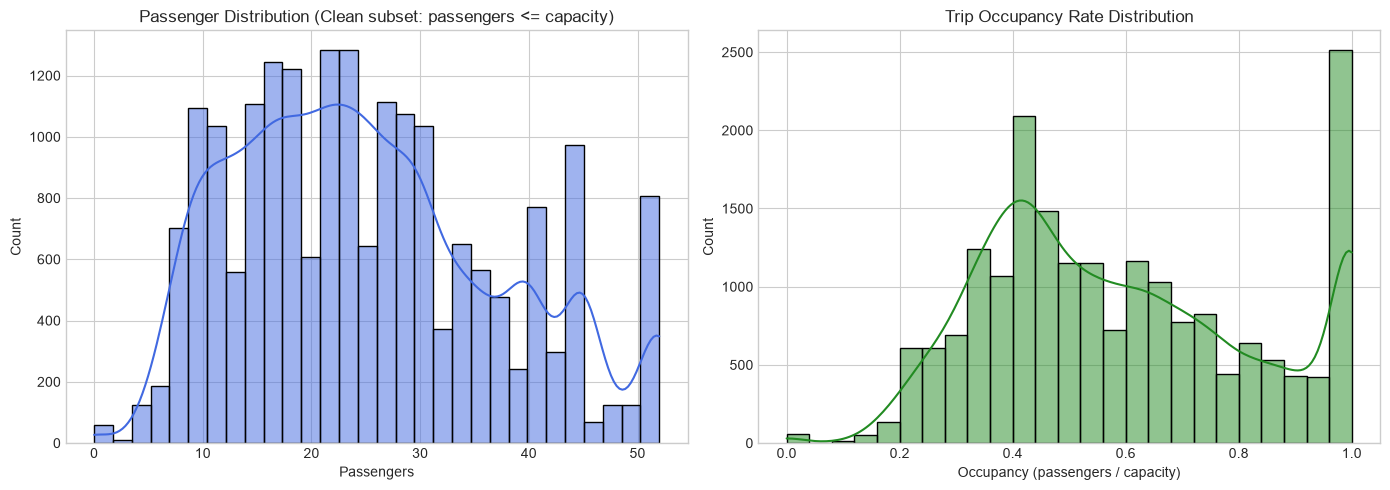

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Histogram of passengers (excluding typing errors where passengers > capacity)
clean_subset = df[df['passengers'] <= df['capacity']]
sns.histplot(clean_subset['passengers'], kde=True, bins=30, ax=axes[0], color='royalblue')
axes[0].set_title('Passenger Distribution (Clean subset: passengers <= capacity)')
axes[0].set_xlabel('Passengers')

# Occupancy distribution
sns.histplot(clean_subset['occupancy'], kde=True, bins=25, ax=axes[1], color='forestgreen')
axes[1].set_title('Trip Occupancy Rate Distribution')
axes[1].set_xlabel('Occupancy (passengers / capacity)')

plt.tight_layout()
plt.show()

### 5. Demand Patterns by Route Type & Calendar Dynamics

C:\Users\Aditya Rai\AppData\Local\Temp\ipykernel_5344\3228560981.py:5: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar=None` for the same effect.

  sns.barplot(data=clean_df, x='route_type', y='passengers', hue='is_weekend', ci=None, palette='Set2')


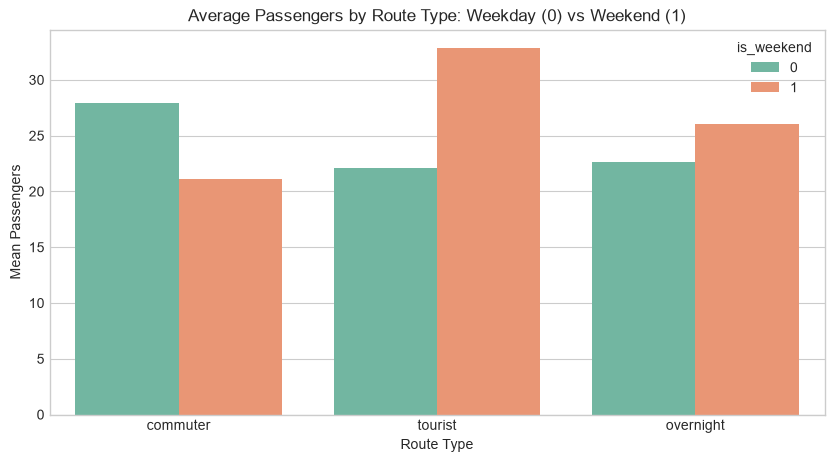

In [5]:
# Weekday vs Weekend by route type
clean_df = df[df['passengers'] <= df['capacity']].drop_duplicates('trip_id')

plt.figure(figsize=(10, 5))
sns.barplot(data=clean_df, x='route_type', y='passengers', hue='is_weekend', ci=None, palette='Set2')
plt.title('Average Passengers by Route Type: Weekday (0) vs Weekend (1)')
plt.ylabel('Mean Passengers')
plt.xlabel('Route Type')
plt.show()

C:\Users\Aditya Rai\AppData\Local\Temp\ipykernel_5344\1661741586.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean_df, x='is_peak', y='passengers', ax=axes[0], palette='Blues')
C:\Users\Aditya Rai\AppData\Local\Temp\ipykernel_5344\1661741586.py:6: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[0].set_xticklabels(['Off-Peak', 'Peak'])
C:\Users\Aditya Rai\AppData\Local\Temp\ipykernel_5344\1661741586.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=clean_df, x='is_holiday', y='passengers', ax=axes[1], palette='Purples')
C:\Users\Aditya Rai\AppData\Lo

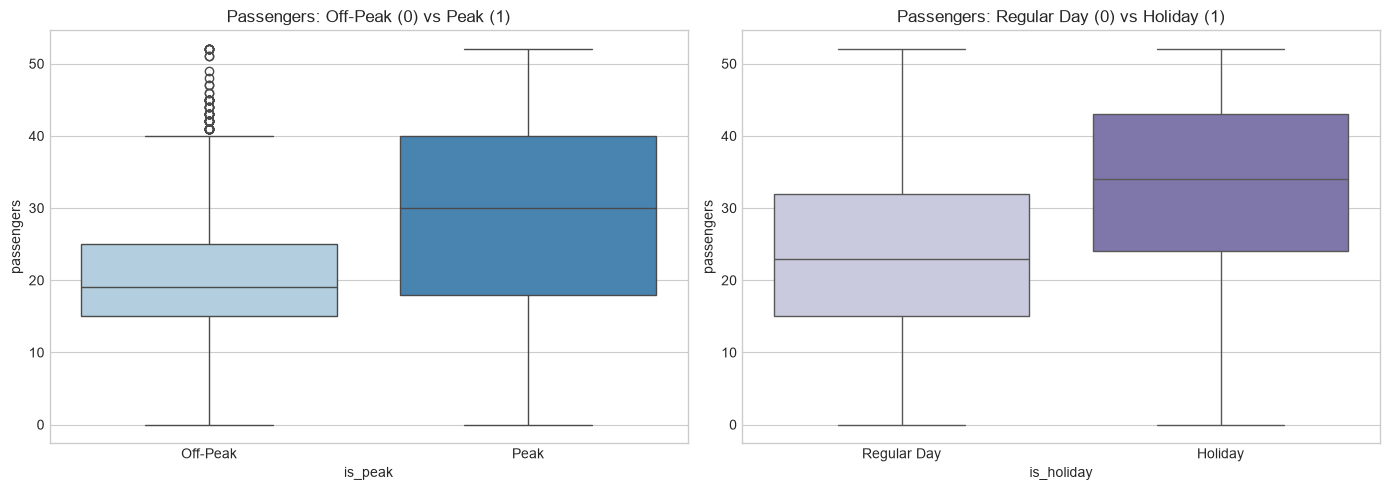

In [6]:
# Peak vs Off-Peak hours and Holiday impact
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=clean_df, x='is_peak', y='passengers', ax=axes[0], palette='Blues')
axes[0].set_title('Passengers: Off-Peak (0) vs Peak (1)')
axes[0].set_xticklabels(['Off-Peak', 'Peak'])

sns.boxplot(data=clean_df, x='is_holiday', y='passengers', ax=axes[1], palette='Purples')
axes[1].set_title('Passengers: Regular Day (0) vs Holiday (1)')
axes[1].set_xticklabels(['Regular Day', 'Holiday'])

plt.tight_layout()
plt.show()

### 6. Route-Level Overview & Cold-Start Route (R10)

In [7]:
# Average passengers and trip counts per route
route_summary = clean_df.groupby(['route_id', 'origin', 'destination', 'route_type']).agg(
    total_trips=('trip_id', 'count'),
    mean_passengers=('passengers', 'mean'),
    mean_occupancy=('occupancy', 'mean'),
    first_date=('departure_datetime', 'min'),
    last_date=('departure_datetime', 'max')
).reset_index()

print("=== Route Performance & Date Ranges ===")
route_summary

=== Route Performance & Date Ranges ===


,route_id,origin,destination,route_type,total_trips,mean_passengers,mean_occupancy,first_date,last_date
0,R01,Delhi,Chandigarh,commuter,2905,36.810327,0.715515,2024-11-01 06:30:00,2026-10-31 17:30:00
1,R02,Chandigarh,Manali,tourist,1455,22.112715,0.551652,2024-11-01 07:00:00,2026-10-31 21:00:00
2,R03,Delhi,Jaipur,commuter,2906,31.003097,0.693993,2024-11-01 06:00:00,2026-10-31 20:30:00
3,R04,Jalandhar,Delhi,overnight,2180,22.103670,0.552282,2024-11-01 07:30:00,2026-10-31 23:00:00
4,R05,Delhi,Manali,overnight,1452,18.996556,0.624251,2024-11-01 17:30:00,2026-10-31 20:30:00
5,R06,Delhi,Dehradun,tourist,2182,28.565995,0.637754,2024-11-01 06:30:00,2026-10-31 16:00:00
6,R07,Chandigarh,Shimla,tourist,2180,24.202294,0.605418,2024-11-01 07:30:00,2026-10-31 17:00:00
7,R08,Delhi,Amritsar,overnight,1453,30.358568,0.591829,2024-11-01 08:00:00,2026-10-31 22:00:00
8,R09,Ludhiana,Chandigarh,commuter,2909,10.088003,0.332084,2024-11-01 06:30:00,2026-10-31 17:00:00
9,R10,Delhi,Rishikesh,tourist,183,21.349727,0.532489,2026-08-01 06:30:00,2026-10-31 14:00:00


### 7. Baseline Model: Hierarchical Historical Means (with Cold-Start Fallback)

**Why this baseline?**
1. **Chronological 80/20 Split:** We split trips by date (first 80% train, last 20% test). In forecasting, you never randomly shuffle time series data (that causes data leakage).
2. **Hierarchical Prediction:**
   - **Primary Guess:** Historical average passengers on that specific route, weekday, and peak status: `(route_id, weekday, is_peak)`.
   - **Cold-Start Fallback:** Route `R10` (Delhi-Rishikesh) launches in August 2026, which is inside the test set! It has 0 history in training. For R10, we fall back to other tourist routes: `(route_type, weekday, is_peak)`.
   - **Global Fallback:** Overall training mean.
3. **Metric (WAPE):** Standard metric for demand forecasting (sum of errors / sum of actuals).

In [8]:
# 1. Clean data: drop duplicate trips and remove typing outliers
clean_df = df.drop_duplicates('trip_id').copy()
clean_df = clean_df[clean_df['passengers'] <= clean_df['capacity']].copy()
clean_df['date'] = clean_df['departure_datetime'].dt.normalize()

# 2. Chronological Split (first 80% dates for train, last 20% for test)
unique_dates = np.sort(clean_df['date'].unique())
cutoff = unique_dates[int(0.8 * len(unique_dates))]
train = clean_df[clean_df['date'] < cutoff].copy()
test = clean_df[clean_df['date'] >= cutoff].copy()

print(f"Train period: {train['date'].min().date()} to {train['date'].max().date()} ({len(train):,} rows)")
print(f"Test period:  {test['date'].min().date()} to {test['date'].max().date()} ({len(test):,} rows)")

# 3. Compute Historical Means
grp_primary = train.groupby(['route_id', 'weekday', 'is_peak'])['passengers'].mean().rename('pred_primary')
grp_fallback = train.groupby(['route_type', 'weekday', 'is_peak'])['passengers'].mean().rename('pred_fallback')
global_mean = train['passengers'].mean()

# 4. Apply Predictions to Test Set
test = test.merge(grp_primary, on=['route_id', 'weekday', 'is_peak'], how='left')
test = test.merge(grp_fallback, on=['route_type', 'weekday', 'is_peak'], how='left')
test['baseline_pred'] = test['pred_primary'].fillna(test['pred_fallback']).fillna(global_mean)

# 5. Evaluate Metrics
def calc_wape(y_true, y_pred):
    return np.sum(np.abs(y_true - y_pred)) / np.sum(y_true)

overall_wape = calc_wape(test['passengers'], test['baseline_pred'])
overall_mae = np.mean(np.abs(test['passengers'] - test['baseline_pred']))
overall_rmse = np.sqrt(np.mean((test['passengers'] - test['baseline_pred'])**2))

print("\n=== BASELINE MODEL RESULTS ===")
print(f"Overall WAPE: {overall_wape*100:.2f}%")
print(f"Overall MAE:  {overall_mae:.2f} passengers")
print(f"Overall RMSE: {overall_rmse:.2f} passengers")

# Evaluate Route R10 (Cold Start)
r10_test = test[test['route_id'] == 'R10']
if len(r10_test) > 0:
    r10_wape = calc_wape(r10_test['passengers'], r10_test['baseline_pred'])
    print(f"\n=== COLD-START ROUTE R10 (Delhi-Rishikesh) ===")
    print(f"R10 Trips in Test Set: {len(r10_test)}")
    print(f"R10 WAPE (via fallback): {r10_wape*100:.2f}%")

Train period: 2024-11-01 to 2026-06-07 (15,699 rows)
Test period:  2026-06-08 to 2026-10-31 (4,106 rows)

=== BASELINE MODEL RESULTS ===
Overall WAPE: 15.70%
Overall MAE:  3.76 passengers
Overall RMSE: 5.23 passengers

=== COLD-START ROUTE R10 (Delhi-Rishikesh) ===
R10 Trips in Test Set: 183
R10 WAPE (via fallback): 20.93%


### 8. Visualize Baseline Predictions vs Actuals

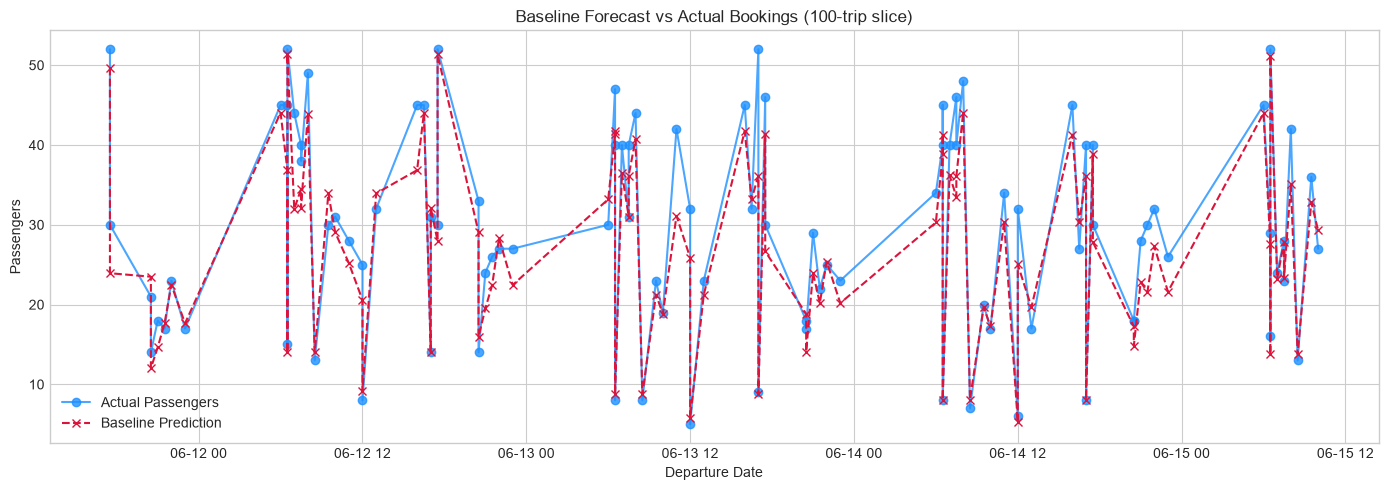

In [9]:
# Sample 100 trips from test set to view predictions vs actuals
sample = test.sort_values('departure_datetime').iloc[100:200]

plt.figure(figsize=(14, 5))
plt.plot(sample['departure_datetime'], sample['passengers'], label='Actual Passengers', marker='o', color='dodgerblue', alpha=0.8)
plt.plot(sample['departure_datetime'], sample['baseline_pred'], label='Baseline Prediction', linestyle='--', marker='x', color='crimson')
plt.title('Baseline Forecast vs Actual Bookings (100-trip slice)')
plt.xlabel('Departure Date')
plt.ylabel('Passengers')
plt.legend()
plt.tight_layout()
plt.show()

### 9. Machine Learning Model: Gradient Boosted Trees (XGBoost)

Now we build a machine learning model using `XGBoostRegressor` to capture nonlinear seasonal interactions, route distances, and holiday effects without leaking target data.

In [10]:
from xgboost import XGBRegressor

# 1. Clean and impute missing distance_km and base_fare deterministically by route
clean_df['distance_km'] = clean_df.groupby('route_id')['distance_km'].transform(lambda x: x.fillna(x.dropna().iloc[0]))
clean_df['base_fare'] = clean_df.groupby(['route_id', 'is_peak'])['base_fare'].transform(lambda x: x.fillna(x.dropna().iloc[0]))

# 2. Feature Engineering (strictly features known 7 days before departure)
clean_df['hour'] = clean_df['departure_datetime'].dt.hour
clean_df['day_of_year'] = clean_df['departure_datetime'].dt.dayofyear

feature_cols = [
    'distance_km', 'capacity', 'base_fare',
    'weekday', 'month', 'hour', 'day_of_year',
    'is_weekend', 'is_peak', 'is_holiday'
]

# One-hot encode route_type and season
clean_encoded = pd.get_dummies(clean_df, columns=['route_type', 'season'], drop_first=True)
dummy_cols = [c for c in clean_encoded.columns if c.startswith(('route_type_', 'season_'))]
all_features = feature_cols + dummy_cols

# 3. Chronological Train/Test Split (same cutoff as baseline)
train_ml = clean_encoded[clean_encoded['date'] < cutoff].copy()
test_ml = clean_encoded[clean_encoded['date'] >= cutoff].copy()

X_train, y_train = train_ml[all_features], train_ml['passengers']
X_test, y_test = test_ml[all_features], test_ml['passengers']

# 4. Fit Model
xgb_model = XGBRegressor(n_estimators=150, max_depth=5, learning_rate=0.08, random_state=42)
xgb_model.fit(X_train, y_train)

# 5. Predict & Enforce Physical Bounds: 0 <= pred <= capacity
raw_preds = xgb_model.predict(X_test)
test_ml['xgb_pred'] = np.clip(np.round(raw_preds), 0, test_ml['capacity'].values)

# 6. Evaluate
xgb_wape = calc_wape(y_test, test_ml['xgb_pred'])
xgb_mae = np.mean(np.abs(y_test - test_ml['xgb_pred']))
xgb_rmse = np.sqrt(np.mean((y_test - test_ml['xgb_pred'])**2))

print("=== XGBOOST MODEL EVALUATION ===")
print(f"XGBoost WAPE: {xgb_wape*100:.2f}% (vs Baseline {overall_wape*100:.2f}%)")
print(f"XGBoost MAE:  {xgb_mae:.2f} passengers (vs Baseline {overall_mae:.2f})")
print(f"XGBoost RMSE: {xgb_rmse:.2f} passengers (vs Baseline {overall_rmse:.2f})")

# Cold-start performance
r10_mask = test_ml['route_id'] == 'R10'
r10_xgb_wape = calc_wape(y_test[r10_mask], test_ml.loc[r10_mask, 'xgb_pred'])
print(f"\n=== COLD-START ROUTE R10 (Delhi-Rishikesh) ===")
print(f"XGBoost R10 WAPE: {r10_xgb_wape*100:.2f}% (vs Baseline {r10_wape*100:.2f}%)")

=== XGBOOST MODEL EVALUATION ===
XGBoost WAPE: 10.02% (vs Baseline 15.70%)
XGBoost MAE:  2.40 passengers (vs Baseline 3.76)
XGBoost RMSE: 3.52 passengers (vs Baseline 5.23)

=== COLD-START ROUTE R10 (Delhi-Rishikesh) ===
XGBoost R10 WAPE: 15.10% (vs Baseline 20.93%)


### 10. Feature Importance & Model Comparison

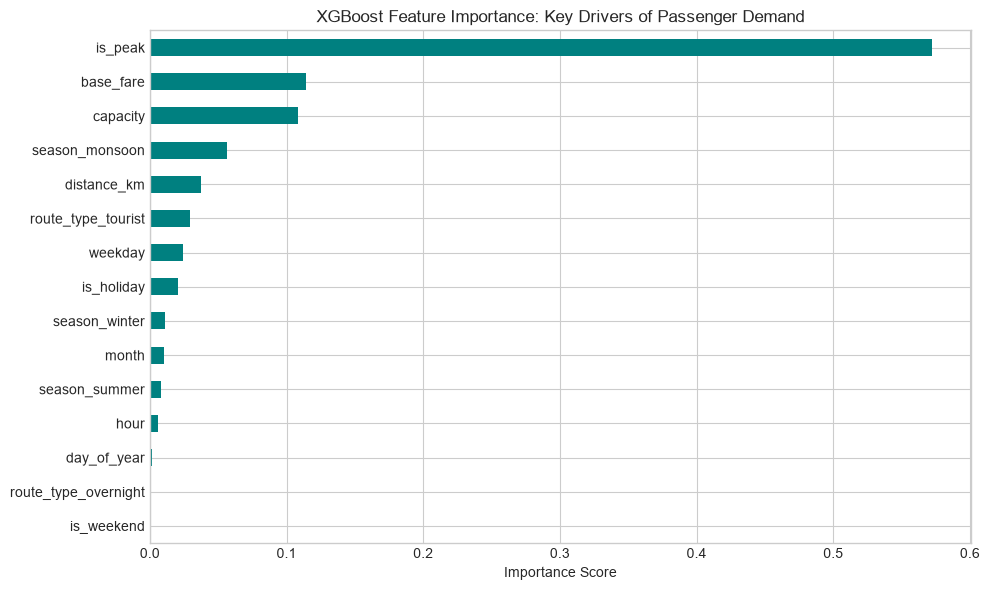

=== FINAL BENCHMARK COMPARISON ===


,Model,Overall WAPE,Overall MAE,Cold-Start R10 WAPE
0,Hierarchical Mean Baseline,15.70%,3.76,20.93%
1,XGBoost Regressor,10.02%,2.40,15.10%


In [11]:
# Plot Feature Importances
feat_imp = pd.Series(xgb_model.feature_importances_, index=all_features).sort_values(ascending=True)

plt.figure(figsize=(10, 6))
feat_imp.plot(kind='barh', color='teal')
plt.title('XGBoost Feature Importance: Key Drivers of Passenger Demand')
plt.xlabel('Importance Score')
plt.tight_layout()
plt.show()

# Final Comparison Table
comparison = pd.DataFrame({
    'Model': ['Hierarchical Mean Baseline', 'XGBoost Regressor'],
    'Overall WAPE': [f"{overall_wape*100:.2f}%", f"{xgb_wape*100:.2f}%"],
    'Overall MAE': [f"{overall_mae:.2f}", f"{xgb_mae:.2f}"],
    'Cold-Start R10 WAPE': [f"{r10_wape*100:.2f}%", f"{r10_xgb_wape*100:.2f}%"]
})
print("=== FINAL BENCHMARK COMPARISON ===")
comparison